In [7]:
!pip install pyspark

In [8]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = SparkSession.builder.appName("delivery_benchmark").getOrCreate()
path = "/content/"

orders = spark.read.csv(path + "olist_orders_dataset.csv", header=True, inferSchema=True)
customers = spark.read.csv(path + "olist_customers_dataset.csv", header=True, inferSchema=True)

print("Orders:", orders.count(), "| Customers:", customers.count())
orders.printSchema()

Orders: 99441 | Customers: 99441
root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)



In [9]:
df = orders.join(customers.select("customer_id", "customer_state"), on="customer_id", how="left")

for c in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    df = df.withColumn(c, F.to_timestamp(c))

total = df.count()
print("Total orders:", total)

Total orders: 99441


In [10]:
checks = {
    "missing_state": df.filter(F.col("customer_state").isNull()).count(),
    "not_delivered": df.filter(F.col("order_status") != "delivered").count(),
    "delivered_but_no_date": df.filter((F.col("order_status") == "delivered") &
                                       F.col("order_delivered_customer_date").isNull()).count(),
    "delivered_before_purchase": df.filter(F.col("order_delivered_customer_date") <
                                           F.col("order_purchase_timestamp")).count(),
    "missing_promise_date": df.filter(F.col("order_estimated_delivery_date").isNull()).count(),
}
for name, n in checks.items():
    print(f"{name}: {n} ({n/total:.2%})")

missing_state: 0 (0.00%)
not_delivered: 2963 (2.98%)
delivered_but_no_date: 8 (0.01%)
delivered_before_purchase: 0 (0.00%)
missing_promise_date: 0 (0.00%)


In [11]:
clean = (df.filter(F.col("order_status") == "delivered")
           .filter(F.col("order_delivered_customer_date").isNotNull())
           .filter(F.col("order_delivered_customer_date") >= F.col("order_purchase_timestamp"))
           .filter(F.col("customer_state").isNotNull()))

n_clean = clean.count()
print(f"Clean orders: {n_clean} ({n_clean/total:.1%} of total)")

Clean orders: 96470 (97.0% of total)


In [12]:
clean = (clean
    .withColumn("delivery_days",
        (F.unix_timestamp("order_delivered_customer_date") - F.unix_timestamp("order_purchase_timestamp")) / 86400)
    .withColumn("is_late",
        (F.to_date("order_delivered_customer_date") > F.to_date("order_estimated_delivery_date")).cast("int"))
    .withColumn("days_vs_promise",
        F.datediff("order_delivered_customer_date", "order_estimated_delivery_date")))

clean.select("customer_state", "delivery_days", "is_late", "days_vs_promise").show(5)

+--------------+------------------+-------+---------------+
|customer_state|     delivery_days|is_late|days_vs_promise|
+--------------+------------------+-------+---------------+
|            SP| 8.436574074074073|      0|             -8|
|            BA|13.782037037037037|      0|             -6|
|            GO| 9.394212962962962|      0|            -18|
|            RN|          13.20875|      0|            -13|
|            SP| 2.873877314814815|      0|            -10|
+--------------+------------------+-------+---------------+
only showing top 5 rows


In [13]:
state_bench = (clean.groupBy("customer_state")
    .agg(F.count("*").alias("orders"),
         F.round(F.percentile_approx("delivery_days", 0.5), 1).alias("median_delivery_days"),
         F.round(F.avg("is_late") * 100, 1).alias("late_pct"),
         F.round(F.avg("days_vs_promise"), 1).alias("avg_days_vs_promise")))

state_bench = state_bench.withColumn("speed_rank", F.rank().over(Window.orderBy("median_delivery_days")))
state_bench.orderBy("speed_rank").show(30)


+--------------+------+--------------------+--------+-------------------+----------+
|customer_state|orders|median_delivery_days|late_pct|avg_days_vs_promise|speed_rank|
+--------------+------+--------------------+--------+-------------------+----------+
|            SP| 40494|                 7.2|     4.5|              -11.1|         1|
|            MG| 11354|                10.3|     4.6|              -13.2|         2|
|            PR|  4923|                10.4|     4.0|              -13.3|         3|
|            DF|  2080|                11.4|     5.7|              -12.0|         4|
|            RJ| 12350|                12.0|    12.1|              -11.8|         5|
|            SC|  3546|                13.0|     8.2|              -11.5|         6|
|            RS|  5344|                13.2|     6.1|              -13.9|         7|
|            ES|  1995|                13.6|    10.7|              -10.5|         8|
|            GO|  1957|                13.9|     6.5|            

In [14]:
weekly = (clean.withColumn("week", F.date_trunc("week", "order_purchase_timestamp"))
    .groupBy("customer_state", "week")
    .agg(F.count("*").alias("orders"),
         F.round(F.percentile_approx("delivery_days", 0.5), 1).alias("median_days"))
    .withColumn("low_volume_flag", F.col("orders") < 30))

flagged = weekly.filter("low_volume_flag").count()
print(f"State-weeks flagged as too thin to trust: {flagged} of {weekly.count()}")

State-weeks flagged as too thin to trust: 1546 of 2152


In [15]:
clean.createOrReplaceTempView("orders_clean")
spark.sql("""
    SELECT customer_state,
           COUNT(*) AS orders,
           ROUND(AVG(is_late) * 100, 1) AS late_pct
    FROM orders_clean
    GROUP BY customer_state
    HAVING COUNT(*) >= 500
    ORDER BY late_pct DESC
    LIMIT 5
""").show()

+--------------+------+--------+
|customer_state|orders|late_pct|
+--------------+------+--------+
|            MA|   717|    17.4|
|            CE|  1279|    13.8|
|            BA|  3256|    12.2|
|            RJ| 12350|    12.1|
|            PA|   946|    11.2|
+--------------+------+--------+



In [16]:
import pandas as pd
from scipy.stats import chi2_contingency, ttest_ind, pearsonr

pdf = clean.select("customer_state", "delivery_days", "is_late").toPandas()

# Chi-squared: does the late-delivery rate differ by state?
big_states = pdf["customer_state"].value_counts()
big_states = big_states[big_states >= 1000].index
sub = pdf[pdf["customer_state"].isin(big_states)]
table = pd.crosstab(sub["customer_state"], sub["is_late"])
chi2, p_chi, dof, _ = chi2_contingency(table)
print(f"Chi-squared ({len(big_states)} states): chi2={chi2:.1f}, dof={dof}, p={p_chi:.2e}")

# t-test: SP vs RJ delivery time
sp = pdf.loc[pdf["customer_state"] == "SP", "delivery_days"]
rj = pdf.loc[pdf["customer_state"] == "RJ", "delivery_days"]
t, p_t = ttest_ind(sp, rj, equal_var=False)
print(f"SP mean {sp.mean():.1f} days vs RJ mean {rj.mean():.1f} days: t={t:.1f}, p={p_t:.2e}")

# Promise padding vs late rate across all 27 states
sbp = state_bench.toPandas()
r, p_r = pearsonr(sbp["avg_days_vs_promise"], sbp["late_pct"])
print(f"Correlation of promise padding with late rate: r={r:.2f}, p={p_r:.3f}")

Chi-squared (12 states): chi2=1418.4, dof=11, p=1.32e-297
SP mean 8.8 days vs RJ mean 15.3 days: t=-60.1, p=0.00e+00
Correlation of promise padding with late rate: r=0.68, p=0.000


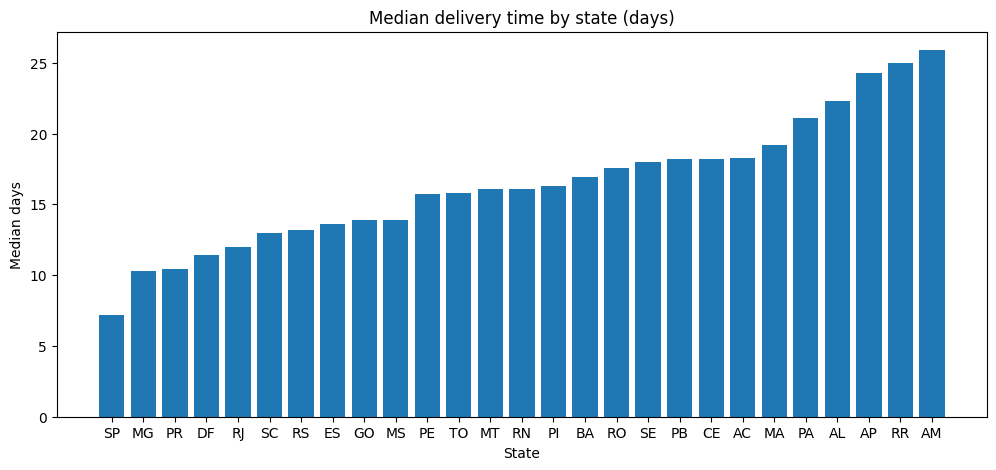

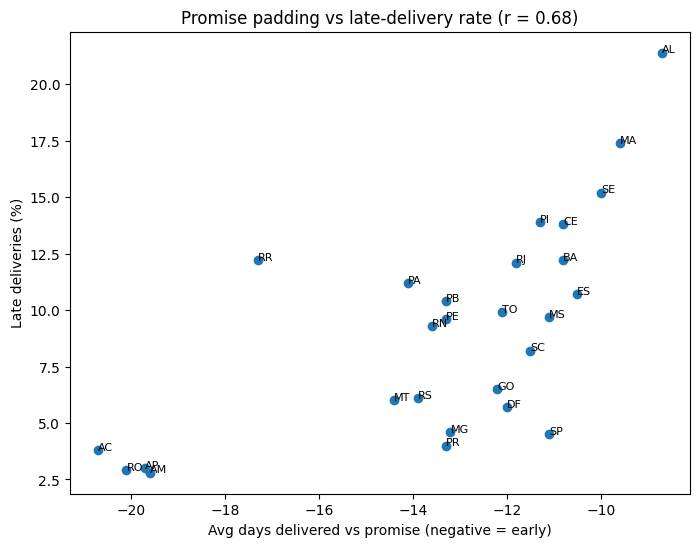

Saved.


In [17]:
import matplotlib.pyplot as plt

sb = state_bench.orderBy("median_delivery_days").toPandas()

# Chart 1: median delivery time by state
plt.figure(figsize=(12, 5))
plt.bar(sb["customer_state"], sb["median_delivery_days"])
plt.title("Median delivery time by state (days)")
plt.xlabel("State"); plt.ylabel("Median days")
plt.savefig("/content/median_delivery_by_state.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart 2: promise padding vs late rate
plt.figure(figsize=(8, 6))
plt.scatter(sb["avg_days_vs_promise"], sb["late_pct"])
for _, row in sb.iterrows():
    plt.annotate(row["customer_state"], (row["avg_days_vs_promise"], row["late_pct"]), fontsize=8)
plt.title("Promise padding vs late-delivery rate (r = 0.68)")
plt.xlabel("Avg days delivered vs promise (negative = early)")
plt.ylabel("Late deliveries (%)")
plt.savefig("/content/promise_padding_vs_late_rate.png", dpi=150, bbox_inches="tight")
plt.show()

sb.to_csv("/content/state_benchmark.csv", index=False)
print("Saved.")